Read an unsupervised dataset and group it based on similarity using K-Means clustering algorithm

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"

columns = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel_Length",
    "Kernel_Width",
    "Asymmetry",
    "Groove_Length",
    "Variety"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (210, 8)

First five records:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area           210 non-null    float64
 1   Perimeter      210 non-null    float64
 2   Compactness    210 non-null    float64
 3   Kernel_Length  210 non-null    float64
 4   Kernel_Width   210 non-null    float64
 5   Asymmetry      210 non-null    float64
 6   Groove_Length  210 non-null    float64
 7   Variety        210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Missing values:
Area             0
Perimeter        0
Compactness      0
Kernel_Length    0
Kernel_Width     0
Asymmetry        0
Groove_Length    0
Variety          0
dtype: int64


In [19]:
X = df.drop(columns=["Variety"])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Number of records:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Feature scaling completed!
Number of records: 210
Number of features: 7


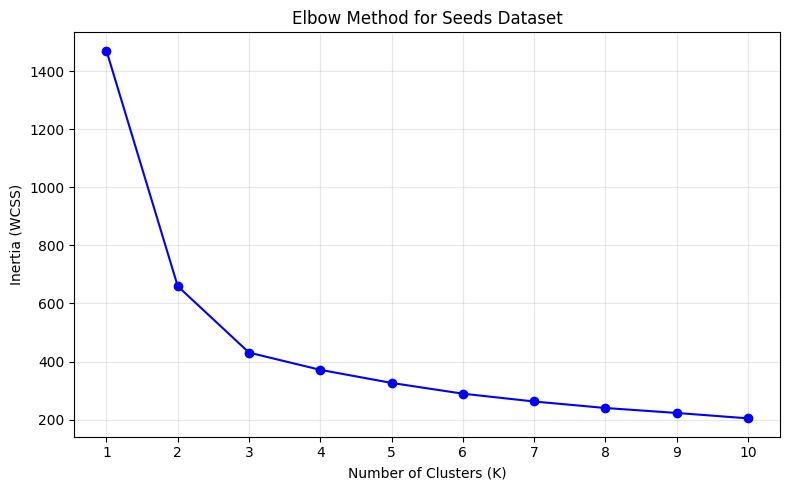

In [20]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o", color="blue")

plt.title("Elbow Method for Seeds Dataset")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

labels = kmeans.fit_predict(X_scaled)

# Add cluster assignments to the dataset
df["Cluster"] = labels

print("K-Means clustering completed!")

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nFirst ten clustered records:")
display(df.head(10))

K-Means clustering completed!

Number of records in each cluster:
Cluster
0    72
1    67
2    71
Name: count, dtype: int64

First ten clustered records:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length,Variety,Cluster
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,2
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,2
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,2
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,2
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,2
5,14.38,14.21,0.8951,5.386,3.312,2.462,4.956,1,2
6,14.69,14.49,0.8799,5.563,3.259,3.586,5.219,1,2
7,14.11,14.10,0.8911,5.420,3.302,2.700,5.000,1,2
8,16.63,15.46,0.8747,6.053,3.465,2.040,5.877,1,1
9,16.44,15.25,0.8880,5.884,3.505,1.969,5.533,1,2


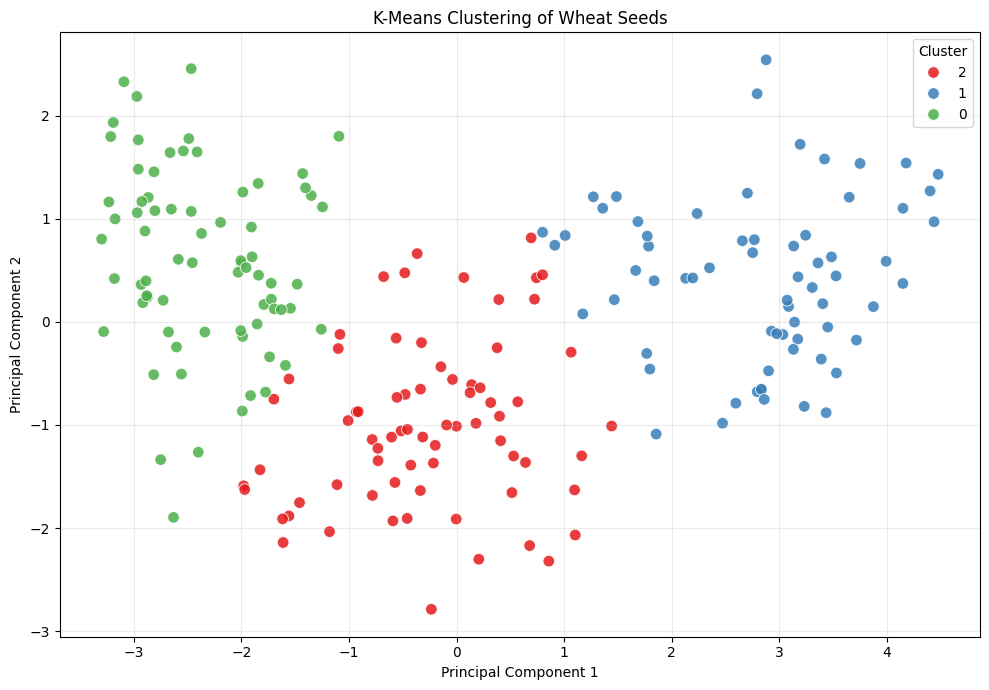

Variance explained by the two PCA components: 88.98%


In [22]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=70,
    alpha=0.85
)

plt.title("K-Means Clustering of Wheat Seeds")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

explained_variance = pca.explained_variance_ratio_.sum() * 100

print(
    f"Variance explained by the two PCA components: "
    f"{explained_variance:.2f}%"
)

In [23]:
score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", round(score, 4))
print("Inertia (WCSS):", round(kmeans.inertia_, 4))

Silhouette Score: 0.4007
Inertia (WCSS): 430.659


In [24]:
print("Average measurements for each cluster:")

cluster_summary = df.groupby("Cluster")[X.columns].mean().round(3)

display(cluster_summary)

print("\nCluster sizes:")
display(
    df["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Number of Records")
)

Average measurements for each cluster:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry,Groove_Length
Cluster,,,,,,,
0,11.857,13.248,0.848,5.232,2.850,4.742,5.102
1,18.495,16.203,0.884,6.176,3.698,3.632,6.042
2,14.438,14.338,0.882,5.515,3.259,2.707,5.121



Cluster sizes:


,Number of Records
Cluster,
0,72
1,67
2,71
